In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("GPU not detected. Training would run on CPU.")

PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
CUDA available: True
GPU: NVIDIA GeForce GTX 1650
GPU memory: 4.0 GB


In [2]:
from pathlib import Path
import pandas as pd
import json
import numpy as np

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

train_df = pd.read_csv(PROJECT_ROOT / "data" / "splits" / "train.csv")
val_df = pd.read_csv(PROJECT_ROOT / "data" / "splits" / "validation.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data" / "splits" / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Classes:", train_df["class_name"].nunique())

assert set(train_df["class_name"]) == set(val_df["class_name"])
assert set(train_df["class_name"]) == set(test_df["class_name"])

class_names = sorted(train_df["class_name"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

with open(models_dir / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=2)

print("Class mapping saved.")

Project root: c:\Users\Hey_Nerd\Desktop\plant-disease-classifier
Training images: 38797
Validation images: 8314
Test images: 8314
Classes: 39
Class mapping saved.


## Cell 3 — Configure image loading

In [3]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMG_SIZE = 224
BATCH_SIZE = 8
SEED = 42

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

def resolve_image_path(file_path):
    path = Path(str(file_path))

    if path.is_absolute():
        return path

    # Support paths stored relative to the project root or dataset root.
    candidates = [
        PROJECT_ROOT / path,
        PROJECT_ROOT / "data" / "raw" / path,
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(f"Image not found: {file_path}")

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class PlantDiseaseDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = resolve_image_path(row["file_path"])

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["class_name"]]

        return image, label

train_dataset = PlantDiseaseDataset(train_df, train_transform)
val_dataset = PlantDiseaseDataset(val_df, eval_transform)
test_dataset = PlantDiseaseDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in first batch:", labels.tolist())

Training device: cuda
Image batch shape: torch.Size([8, 3, 224, 224])
Label batch shape: torch.Size([8])
Labels in first batch: [5, 16, 26, 16, 15, 14, 14, 36]


## Cell 4 — Build MobileNetV2

In [4]:
import torch.nn as nn
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

weights = MobileNet_V2_Weights.DEFAULT
model = mobilenet_v2(weights=weights)

# Freeze the pretrained feature extractor initially.
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Replace the original 1000-class ImageNet output with our 39 classes.
in_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, NUM_CLASSES)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=1e-3
)

print("Model:", "MobileNetV2")
print("Number of classes:", NUM_CLASSES)
print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\Hey_Nerd/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 14.8MB/s]

Model: MobileNetV2
Number of classes: 39
Device: cuda
Trainable parameters: 49959


## Cell 5 — Train the classification head

In [5]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import copy
import time

EPOCHS = 10
PATIENCE = 3

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0
history = []

checkpoint_path = models_dir / "plant_disease_mobilenetv2_best.pth"

for epoch in range(EPOCHS):
    start_time = time.time()

    # Training
    model.train()
    running_loss = 0.0
    train_true, train_pred = [], []

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for images, labels in progress:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().tolist())
        train_pred.extend(predictions.cpu().tolist())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / len(train_dataset)
    train_accuracy = accuracy_score(train_true, train_pred)
    train_macro_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # Validation
    model.eval()
    val_loss_total = 0.0
    val_true, val_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss = val_loss_total / len(val_dataset)
    val_accuracy = accuracy_score(val_true, val_pred)
    val_macro_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    metrics = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
    }
    history.append(metrics)

    print(
        f"\nEpoch {epoch + 1}: "
        f"train_loss={train_loss:.4f}, "
        f"train_acc={train_accuracy:.4f}, "
        f"val_loss={val_loss:.4f}, "
        f"val_acc={val_accuracy:.4f}, "
        f"val_macro_f1={val_macro_f1:.4f}, "
        f"time={time.time() - start_time:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": best_state,
            "class_names": class_names,
            "img_size": IMG_SIZE,
            "num_classes": NUM_CLASSES,
        }, checkpoint_path)

        print("Saved best model:", checkpoint_path)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

# Restore the best validation-loss checkpoint.
if best_state is not None:
    model.load_state_dict(best_state)

history_df = pd.DataFrame(history)
history_df.to_csv(
    PROJECT_ROOT / "reports" / "mobilenetv2_training_history.csv",
    index=False
)

history_df

c:\Users\Hey_Nerd\Desktop\plant-disease-classifier\.venv-pytorch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Epoch 1/10: 100%|██████████| 4850/4850 [02:59<00:00, 26.97it/s, loss=0.5360]



Epoch 1: train_loss=0.6500, train_acc=0.8316, val_loss=0.2145, val_acc=0.9385, val_macro_f1=0.9219, time=213.7s
Saved best model: c:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\plant_disease_mobilenetv2_best.pth


Epoch 2/10: 100%|██████████| 4850/4850 [02:52<00:00, 28.08it/s, loss=2.3311]



Epoch 2: train_loss=0.3525, train_acc=0.8909, val_loss=0.1650, val_acc=0.9464, val_macro_f1=0.9354, time=205.2s
Saved best model: c:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\plant_disease_mobilenetv2_best.pth


Epoch 3/10: 100%|██████████| 4850/4850 [02:52<00:00, 28.07it/s, loss=0.5281]


...

Epoch 9/10: 100%|██████████| 4850/4850 [02:43<00:00, 29.67it/s, loss=0.0696]



Epoch 9: train_loss=0.2817, train_acc=0.9104, val_loss=0.1263, val_acc=0.9574, val_macro_f1=0.9451, time=193.8s


Epoch 10/10: 100%|██████████| 4850/4850 [02:43<00:00, 29.69it/s, loss=0.6025]



Epoch 10: train_loss=0.2781, train_acc=0.9096, val_loss=0.1357, val_acc=0.9535, val_macro_f1=0.9431, time=193.6s
Early stopping.


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,0.650028,0.831585,0.791567,0.214528,0.938537,0.921903
1,2,0.352516,0.890945,0.870992,0.164978,0.946356,0.935388
2,3,0.320554,0.897131,0.880954,0.132469,0.957902,0.948096
3,4,0.302225,0.903188,0.887877,0.135187,0.953452,0.942771
4,5,0.292149,0.907029,0.892728,0.138367,0.953452,0.939536
5,6,0.289089,0.905766,0.889877,0.120767,0.958504,0.950324
6,7,0.289583,0.908240,0.893422,0.119735,0.958023,0.948271
7,8,0.290926,0.906075,0.891674,0.125996,0.959225,0.950747
8,9,0.281720,0.910354,0.896339,0.126251,0.957421,0.945145
9,10,0.278060,0.909606,0.896074,0.135668,0.953452,0.943070


## Cell 6 — Plot the learning curves

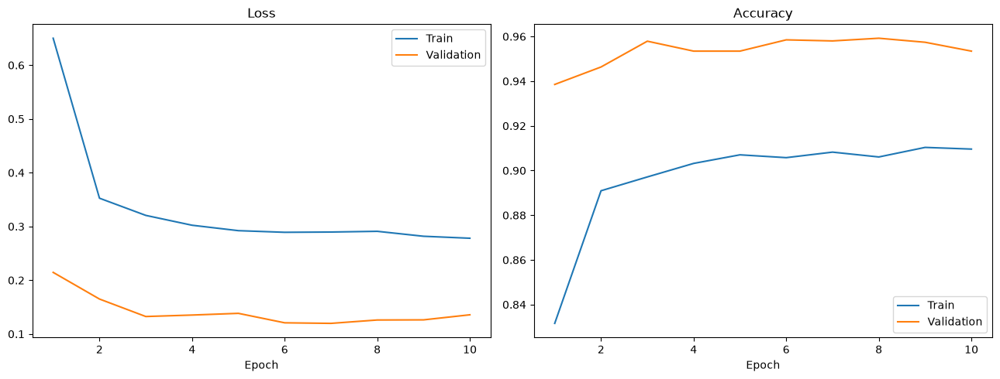

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"], label="Train"
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"], label="Validation"
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
print(history_df.columns.tolist())
print(history_df.to_string(index=False))

['epoch', 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1']
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     1    0.650028        0.831585        0.791567  0.214528      0.938537      0.921903
     2    0.352516        0.890945        0.870992  0.164978      0.946356      0.935388
     3    0.320554        0.897131        0.880954  0.132469      0.957902      0.948096
     4    0.302225        0.903188        0.887877  0.135187      0.953452      0.942771
     5    0.292149        0.907029        0.892728  0.138367      0.953452      0.939536
     6    0.289089        0.905766        0.889877  0.120767      0.958504      0.950324
     7    0.289583        0.908240        0.893422  0.119735      0.958023      0.948271
     8    0.290926        0.906075        0.891674  0.125996      0.959225      0.950747
     9    0.281720        0.910354        0.896339  0.126251      0.957421      0.945145
    10

In [8]:
print("Best validation loss:")
print(history_df.loc[history_df["val_loss"].idxmin()])

print("\nBest validation accuracy:")
print(history_df.loc[history_df["val_accuracy"].idxmax()])

print("\nBest validation macro F1:")
print(history_df.loc[history_df["val_macro_f1"].idxmax()])

Best validation loss:
epoch             7.000000
train_loss        0.289583
train_accuracy    0.908240
train_macro_f1    0.893422
val_loss          0.119735
val_accuracy      0.958023
val_macro_f1      0.948271
Name: 6, dtype: float64

Best validation accuracy:
epoch             8.000000
train_loss        0.290926
train_accuracy    0.906075
train_macro_f1    0.891674
val_loss          0.125996
val_accuracy      0.959225
val_macro_f1      0.950747
Name: 7, dtype: float64

Best validation macro F1:
epoch             8.000000
train_loss        0.290926
train_accuracy    0.906075
train_macro_f1    0.891674
val_loss          0.125996
val_accuracy      0.959225
val_macro_f1      0.950747
Name: 7, dtype: float64


# fine-tune MobileNetV2

## Cell 1 — Load the best checkpoint

In [9]:
import torch
from torchvision.models import mobilenet_v2
import torch.nn as nn

checkpoint_path = models_dir / "plant_disease_mobilenetv2_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model = mobilenet_v2(weights=None)

in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, NUM_CLASSES)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

print("Checkpoint loaded.")
print("Saved classes:", len(checkpoint["class_names"]))

Checkpoint loaded.
Saved classes: 39


## Cell 2 — Unfreeze the final feature blocks

In [10]:
# Freeze all feature layers first.
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Unfreeze only the later feature blocks.
for parameter in model.features[-3:].parameters():
    parameter.requires_grad = True

# Keep the classifier trainable.
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5
)

criterion = nn.CrossEntropyLoss()

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Trainable parameters: 1256039


## Cell 3 — Fine-tune for up to 8 epochs

In [11]:
import copy
import time
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

FINE_TUNE_EPOCHS = 8
PATIENCE = 3

best_ft_loss = float("inf")
best_ft_state = None
no_improvement = 0
fine_tune_history = []

fine_tune_path = models_dir / "plant_disease_mobilenetv2_finetuned_best.pth"

for epoch in range(FINE_TUNE_EPOCHS):
    start = time.time()
    model.train()

    train_loss_sum = 0.0
    train_true, train_pred = [], []

    for images, labels in tqdm(
        train_loader,
        desc=f"Fine-tuning {epoch + 1}/{FINE_TUNE_EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(outputs.argmax(1).detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_dataset)
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    model.eval()
    val_loss_sum = 0.0
    val_true, val_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(outputs.argmax(1).cpu().tolist())

    val_loss = val_loss_sum / len(val_dataset)
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
    }
    fine_tune_history.append(row)

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.4f} | "
        f"Val macro F1: {val_f1:.4f} | "
        f"Time: {time.time() - start:.1f}s"
    )

    if val_loss < best_ft_loss:
        best_ft_loss = val_loss
        best_ft_state = copy.deepcopy(model.state_dict())
        no_improvement = 0

        torch.save({
            "model_state_dict": best_ft_state,
            "class_names": class_names,
            "img_size": IMG_SIZE,
            "num_classes": NUM_CLASSES,
        }, fine_tune_path)

        print("Best fine-tuned checkpoint saved.")
    else:
        no_improvement += 1

    if no_improvement >= PATIENCE:
        print("Early stopping.")
        break

fine_tune_df = pd.DataFrame(fine_tune_history)
fine_tune_df

Fine-tuning 1/8: 100%|██████████| 4850/4850 [02:56<00:00, 27.55it/s]


Train loss: 0.2325 | Val loss: 0.1001 | Val accuracy: 0.9674 | Val macro F1: 0.9591 | Time: 206.8s
Best fine-tuned checkpoint saved.


Fine-tuning 2/8: 100%|██████████| 4850/4850 [02:56<00:00, 27.42it/s]


Train loss: 0.1887 | Val loss: 0.0833 | Val accuracy: 0.9723 | Val macro F1: 0.9655 | Time: 207.8s
Best fine-tuned checkpoint saved.


Fine-tuning 3/8: 100%|██████████| 4850/4850 [02:57<00:00, 27.32it/s]


...

Fine-tuning 7/8: 100%|██████████| 4850/4850 [02:57<00:00, 27.28it/s]


Train loss: 0.1186 | Val loss: 0.0508 | Val accuracy: 0.9830 | Val macro F1: 0.9777 | Time: 208.5s
Best fine-tuned checkpoint saved.


Fine-tuning 8/8: 100%|██████████| 4850/4850 [02:57<00:00, 27.39it/s]


Train loss: 0.1030 | Val loss: 0.0515 | Val accuracy: 0.9829 | Val macro F1: 0.9769 | Time: 208.0s


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,0.232468,0.924350,0.912312,0.100089,0.967404,0.959149
1,2,0.188703,0.937856,0.927844,0.083270,0.972336,0.965494
2,3,0.168876,0.945434,0.936272,0.074824,0.974381,0.967523
3,4,0.149154,0.951079,0.942956,0.064687,0.977508,0.971053
4,5,0.138040,0.955022,0.946608,0.055388,0.981838,0.975518
5,6,0.126941,0.958450,0.951520,0.055889,0.981597,0.975950
6,7,0.118615,0.960306,0.953099,0.050826,0.983041,0.977654
7,8,0.103043,0.964791,0.956566,0.051529,0.982920,0.976857


In [12]:
print(fine_tune_df.columns.tolist())
print(fine_tune_df.to_string(index=False))

print("\nBest validation loss:")
print(fine_tune_df.loc[fine_tune_df["val_loss"].idxmin()])

print("\nBest validation accuracy:")
print(fine_tune_df.loc[fine_tune_df["val_accuracy"].idxmax()])

print("\nBest validation macro F1:")
print(fine_tune_df.loc[fine_tune_df["val_macro_f1"].idxmax()])

['epoch', 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1']
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     1    0.232468        0.924350        0.912312  0.100089      0.967404      0.959149
     2    0.188703        0.937856        0.927844  0.083270      0.972336      0.965494
     3    0.168876        0.945434        0.936272  0.074824      0.974381      0.967523
     4    0.149154        0.951079        0.942956  0.064687      0.977508      0.971053
     5    0.138040        0.955022        0.946608  0.055388      0.981838      0.975518
     6    0.126941        0.958450        0.951520  0.055889      0.981597      0.975950
     7    0.118615        0.960306        0.953099  0.050826      0.983041      0.977654
     8    0.103043        0.964791        0.956566  0.051529      0.982920      0.976857

Best validation loss:
epoch             7.000000
train_loss        0.118615
train_accuracy    

## evaluate the test set

In [14]:
import torch
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Load the selected fine-tuned checkpoint
checkpoint_path = models_dir / "plant_disease_mobilenetv2_finetuned_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Evaluate once on the held-out test set
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print(f"Test accuracy:    {test_accuracy:.4%}")
print(f"Test macro F1:    {test_macro_f1:.4%}")
print(f"Test weighted F1: {test_weighted_f1:.4%}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
    digits=4
))

Test accuracy:    98.4243%
Test macro F1:    97.8436%
Test weighted F1: 98.4224%

Classification report:
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     0.9891    0.9681    0.9785        94
                            Apple___Black_rot     1.0000    0.9892    0.9946        93
                     Apple___Cedar_apple_rust     1.0000    0.9756    0.9877        41
                              Apple___healthy     0.9878    0.9918    0.9898       245
                    Background_without_leaves     0.9940    0.9766    0.9853       171
                          Blueberry___healthy     0.9956    1.0000    0.9978       226
                      Cherry___Powdery_mildew     0.9875    1.0000    0.9937       158
                             Cherry___healthy     1.0000    1.0000    1.0000       128
   Corn___Cercospora_leaf_spot Gray_leaf_spot     0.8171    0.8701    0.8428        77
                        

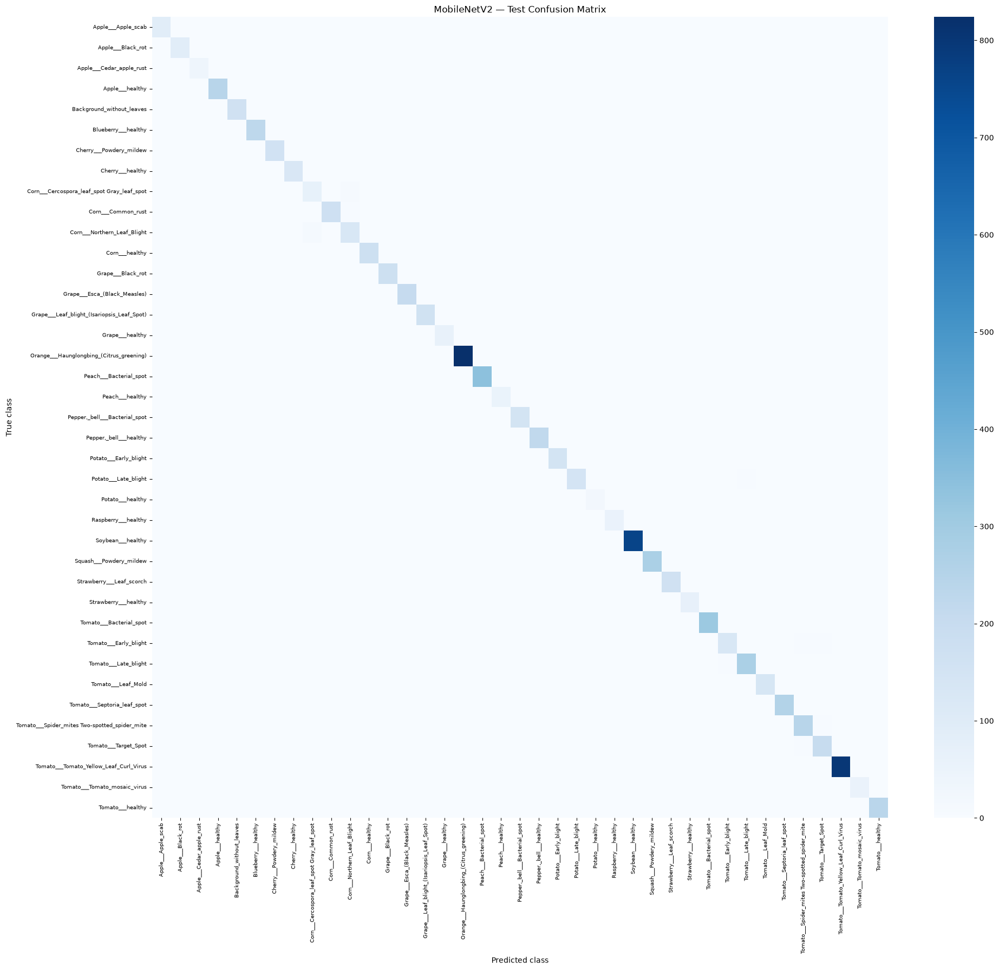

In [15]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)
ax.set_title("MobileNetV2 — Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_report = (
    pd.DataFrame(report)
    .T
    .drop(index=["accuracy", "macro avg", "weighted avg"], errors="ignore")
    .sort_values("recall")
)

display(
    class_report[
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

print("\nFive classes with the lowest recall:")
display(class_report.head(5).round(4))

,precision,recall,f1-score,support
Tomato___Early_blight,0.9281,0.8600,0.8927,150.0
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.8171,0.8701,0.8428,77.0
Corn___Northern_Leaf_Blight,0.8904,0.8844,0.8874,147.0
Tomato___Leaf_Mold,0.9784,0.9510,0.9645,143.0
Tomato___Target_Spot,0.9437,0.9571,0.9504,210.0
Tomato___Spider_mites Two-spotted_spider_mite,0.9490,0.9641,0.9565,251.0
Corn___Common_rust,0.9943,0.9665,0.9802,179.0
Potato___Late_blight,0.9797,0.9667,0.9732,150.0
Apple___Apple_scab,0.9891,0.9681,0.9785,94.0
Tomato___Late_blight,0.9650,0.9684,0.9667,285.0



Five classes with the lowest recall:


,precision,recall,f1-score,support
Tomato___Early_blight,0.9281,0.8600,0.8927,150.0
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.8171,0.8701,0.8428,77.0
Corn___Northern_Leaf_Blight,0.8904,0.8844,0.8874,147.0
Tomato___Leaf_Mold,0.9784,0.9510,0.9645,143.0
Tomato___Target_Spot,0.9437,0.9571,0.9504,210.0


In [17]:
import numpy as np
import pandas as pd

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

errors = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            errors.append({
                "true_class": class_names[true_idx],
                "predicted_class": class_names[pred_idx],
                "mistakes": int(cm[true_idx, pred_idx])
            })

error_df = pd.DataFrame(errors)

if not error_df.empty:
    error_df = error_df.sort_values(
        "mistakes", ascending=False
    ).reset_index(drop=True)

    display(error_df.head(15))
else:
    print("No misclassifications found.")

,true_class,predicted_class,mistakes
0,Corn___Northern_Leaf_Blight,Corn___Cercospora_leaf_spot Gray_leaf_spot,14
1,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight,10
2,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,6
3,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,6
4,Corn___Common_rust,Corn___Northern_Leaf_Blight,5
5,Tomato___Late_blight,Tomato___Early_blight,4
6,Tomato___Early_blight,Tomato___Target_Spot,4
7,Tomato___Early_blight,Tomato___Spider_mites Two-spotted_spider_mite,4
8,Potato___Late_blight,Tomato___Late_blight,4
9,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Tomato_Yellow_Leaf_Curl_Virus,3


Total misclassified test images: 131


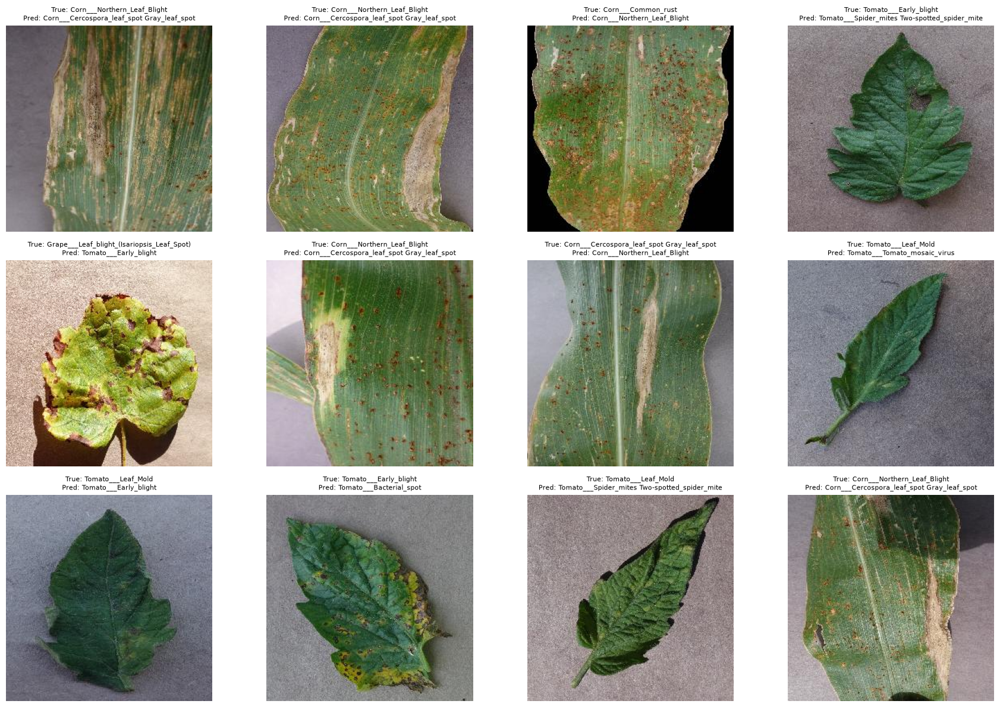

In [18]:
import matplotlib.pyplot as plt
import torch
from PIL import Image

# Recover test image paths in exactly the same order as test_dataset.
mistake_indices = [
    i for i, (true_label, pred_label)
    in enumerate(zip(y_true, y_pred))
    if true_label != pred_label
]

print("Total misclassified test images:", len(mistake_indices))

n_show = min(12, len(mistake_indices))
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, idx in zip(axes, mistake_indices[:n_show]):
    row = test_df.iloc[idx]
    image_path = resolve_image_path(row["file_path"])

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}",
        fontsize=8
    )
    ax.axis("off")

for ax in axes[n_show:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
display(
    class_report[
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("recall").head(10).round(4)
)

,precision,recall,f1-score,support
Tomato___Early_blight,0.9281,0.8600,0.8927,150.0
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.8171,0.8701,0.8428,77.0
Corn___Northern_Leaf_Blight,0.8904,0.8844,0.8874,147.0
Tomato___Leaf_Mold,0.9784,0.9510,0.9645,143.0
Tomato___Target_Spot,0.9437,0.9571,0.9504,210.0
Tomato___Spider_mites Two-spotted_spider_mite,0.9490,0.9641,0.9565,251.0
Corn___Common_rust,0.9943,0.9665,0.9802,179.0
Potato___Late_blight,0.9797,0.9667,0.9732,150.0
Apple___Apple_scab,0.9891,0.9681,0.9785,94.0
Tomato___Late_blight,0.9650,0.9684,0.9667,285.0


## Corn disease classification

In [20]:
focus_classes = [
    "Corn___Northern_Leaf_Blight",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn___Common_rust",
    "Tomato___Early_blight",
    "Tomato___Target_Spot",
]

print("Training examples:")
print(
    train_df[train_df["class_name"].isin(focus_classes)]
    ["class_name"]
    .value_counts()
    .sort_index()
)

print("\nValidation examples:")
print(
    val_df[val_df["class_name"].isin(focus_classes)]
    ["class_name"]
    .value_counts()
    .sort_index()
)

Training examples:
class_name
Corn___Cercospora_leaf_spot Gray_leaf_spot    359
Corn___Common_rust                            834
Corn___Northern_Leaf_Blight                   690
Tomato___Early_blight                         700
Tomato___Target_Spot                          983
Name: count, dtype: int64

Validation examples:
class_name
Corn___Cercospora_leaf_spot Gray_leaf_spot     77
Corn___Common_rust                            179
Corn___Northern_Leaf_Blight                   148
Tomato___Early_blight                         150
Tomato___Target_Spot                          211
Name: count, dtype: int64


In [21]:
import torch
import matplotlib.pyplot as plt
from PIL import Image

corn_a = "Corn___Northern_Leaf_Blight"
corn_b = "Corn___Cercospora_leaf_spot Gray_leaf_spot"

corn_pair_errors = []

model.eval()

with torch.no_grad():
    for idx, (image, label) in enumerate(test_dataset):
        image_batch = image.unsqueeze(0).to(device)
        probabilities = torch.softmax(model(image_batch), dim=1)[0]

        true_idx = int(label)
        pred_idx = int(probabilities.argmax().item())

        true_name = class_names[true_idx]
        pred_name = class_names[pred_idx]

        if (
            true_name in (corn_a, corn_b)
            and pred_name in (corn_a, corn_b)
            and true_idx != pred_idx
        ):
            corn_pair_errors.append({
                "index": idx,
                "true": true_name,
                "predicted": pred_name,
                "confidence": float(probabilities[pred_idx].item()),
            })

print("Corn pair errors:", len(corn_pair_errors))

Corn pair errors: 24


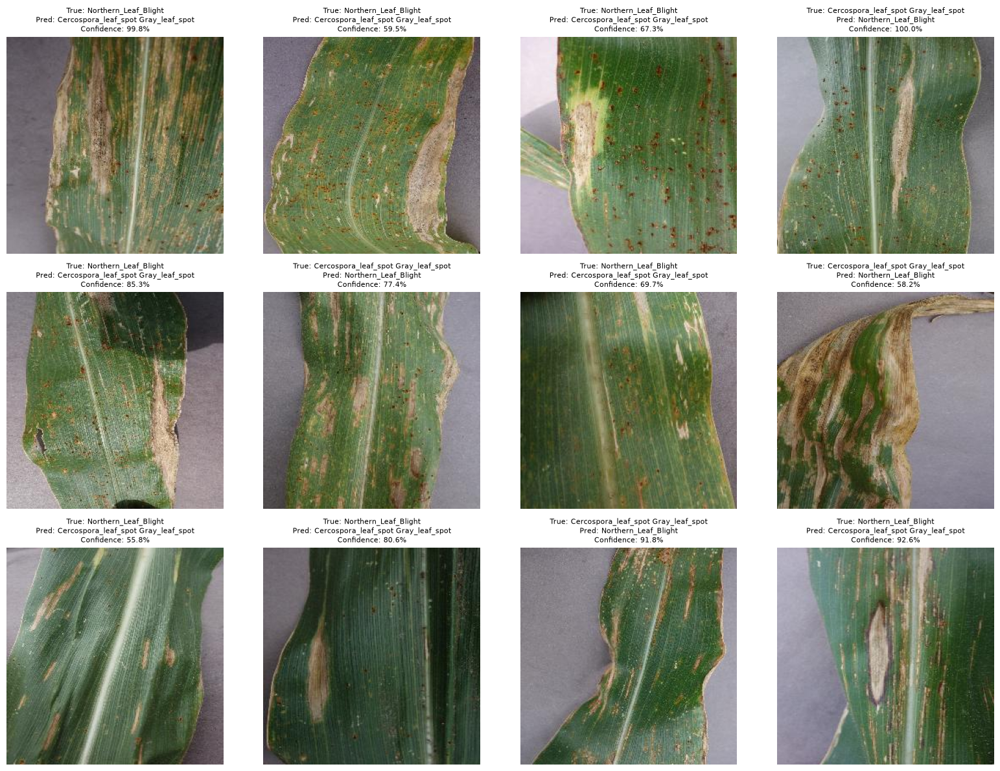

In [22]:
n_show = min(12, len(corn_pair_errors))

if n_show:
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    axes = axes.flatten()

    for ax, item in zip(axes, corn_pair_errors[:n_show]):
        row = test_df.iloc[item["index"]]
        path = resolve_image_path(row["file_path"])

        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"True: {item['true'].replace('Corn___', '')}\n"
            f"Pred: {item['predicted'].replace('Corn___', '')}\n"
            f"Confidence: {item['confidence']:.1%}",
            fontsize=8
        )
        ax.axis("off")

    for ax in axes[n_show:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No errors found between these two corn classes.")

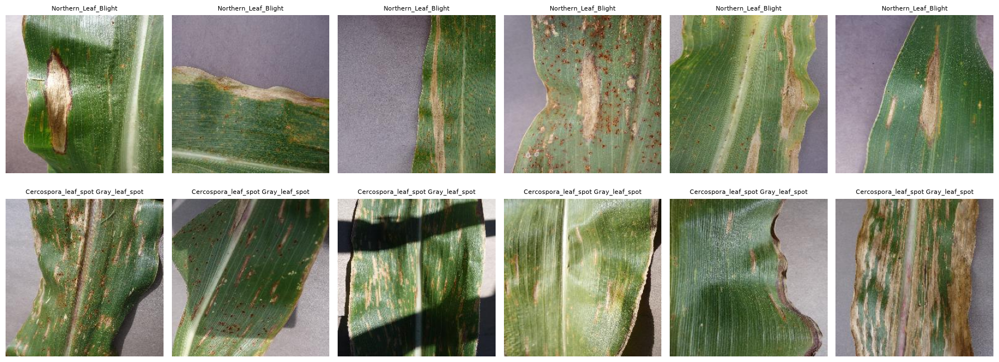

In [23]:
import matplotlib.pyplot as plt
from PIL import Image

corn_classes = [
    "Corn___Northern_Leaf_Blight",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot",
]

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for row_idx, class_name in enumerate(corn_classes):
    sample_df = (
        train_df[train_df["class_name"] == class_name]
        .sample(n=min(6, (train_df["class_name"] == class_name).sum()),
                random_state=42)
    )

    for col_idx, (_, record) in enumerate(sample_df.iterrows()):
        path = resolve_image_path(record["file_path"])

        with Image.open(path) as img:
            axes[row_idx, col_idx].imshow(img.convert("RGB"))

        axes[row_idx, col_idx].set_title(
            class_name.replace("Corn___", ""),
            fontsize=8
        )
        axes[row_idx, col_idx].axis("off")

    for col_idx in range(len(sample_df), 6):
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()

In [24]:
background_class = "Background_without_leaves"

print("Training images:", (train_df["class_name"] == background_class).sum())
print("Validation images:", (val_df["class_name"] == background_class).sum())
print("Test images:", (test_df["class_name"] == background_class).sum())

display(
    train_df.loc[
        train_df["class_name"] == background_class,
        ["file_path", "class_name"]
    ].head(10)
)

Training images: 799
Validation images: 171
Test images: 171


,file_path,class_name
73,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
110,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
172,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
217,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
259,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
270,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
365,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
468,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
485,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves
500,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,Background_without_leaves


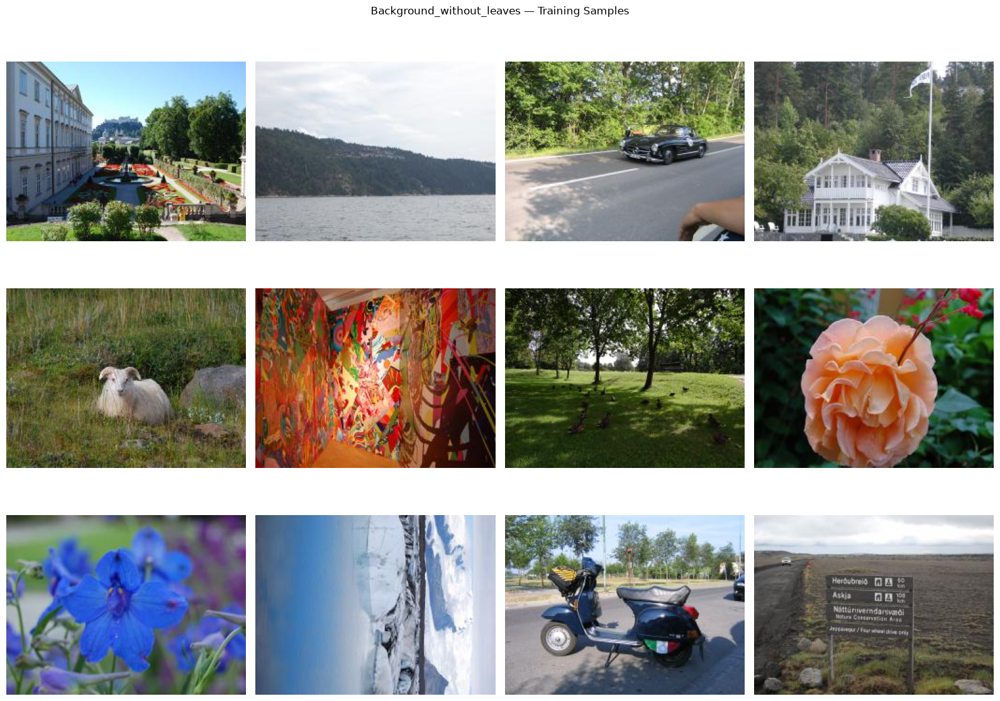

In [25]:
import matplotlib.pyplot as plt
from PIL import Image

background_class = "Background_without_leaves"

sample_df = train_df[
    train_df["class_name"] == background_class
].sample(n=12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    image_path = resolve_image_path(row["file_path"])

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.axis("off")

plt.suptitle("Background_without_leaves — Training Samples")
plt.tight_layout()
plt.show()